# 🇰🇭 Cambodia Food Price Analysis & Prediction
## Machine Learning Course Project | AUPP | 2026

---

### Project Overview
Food price volatility is a critical issue in Cambodia, affecting food security for millions of people.
This project applies machine learning to analyze and predict food commodity prices across Cambodian markets from 2018 to 2026.

### Objectives
- **Predict** next month's commodity prices using historical data
- **Detect** unusual price anomalies across markets and provinces  
- **Classify** whether retail markup over wholesale is above median

### Dataset
- **Source:** World Food Programme (WFP) — VAM Food Security
- **Coverage:** 2003–2026 (modeled from 2018 onwards for data density)
- **Size:** 85,107 records across 25 provinces, 86 markets, 49 commodities

## 1. Setup & Imports
Loading required libraries for data processing, machine learning, and visualization.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, classification_report
from sklearn.ensemble import RandomForestRegressor, GradientBoostingClassifier, IsolationForest
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

os.makedirs("models", exist_ok=True)

## 2. Data Loading & Exploration
We begin by loading the raw WFP Cambodia food price dataset and exploring its structure.

### 2.1 Raw Data Issues Found
Before cleaning, we identify the following problems:
- **Zero prices** — invalid/missing entries recorded as 0
- **Wage data** — non-food commodity mixed in with food prices
- **Sparse early years** — pre-2018 data has under 1,000 rows/year, insufficient for reliable modeling
- **No nulls** — dataset has no missing values but zero prices act as implicit nulls

In [2]:
df_raw = pd.read_csv("/content/drive/MyDrive/wfp_food_prices_khm.csv")
df_raw['date'] = pd.to_datetime(df_raw['date'])


df = df_raw[df_raw['usdprice'] > 0].copy()
df = df[df['commodity'] != 'Wage (non-qualified labour)']
df = df[df['date'].dt.year >= 2018]
df = df.drop_duplicates()
df = df.sort_values(['commodity', 'market', 'pricetype', 'date']).reset_index(drop=True)

print(f"Shape: {df.shape}")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
print(f"Commodities: {df['commodity'].nunique()}")
print(f"Provinces: {df['admin1'].nunique()}")

Shape: (79532, 16)
Date range: 2018-01-15 00:00:00 to 2026-03-15 00:00:00
Commodities: 49
Provinces: 25


### 2.2 Price Trend 2003–2026
Visualizing the long-term average food price trend across all commodities in Cambodia.
Key events are highlighted:
- 🔴 **COVID-19 period (2019–2021):** Supply chain disruptions caused price volatility
- 🟠 **Post-COVID inflation (2021–2023):** Global inflation pushed prices to record highs
- 🟡 **2024–2025:** Gradual stabilization with some geopolitical impact on oil-linked commodities

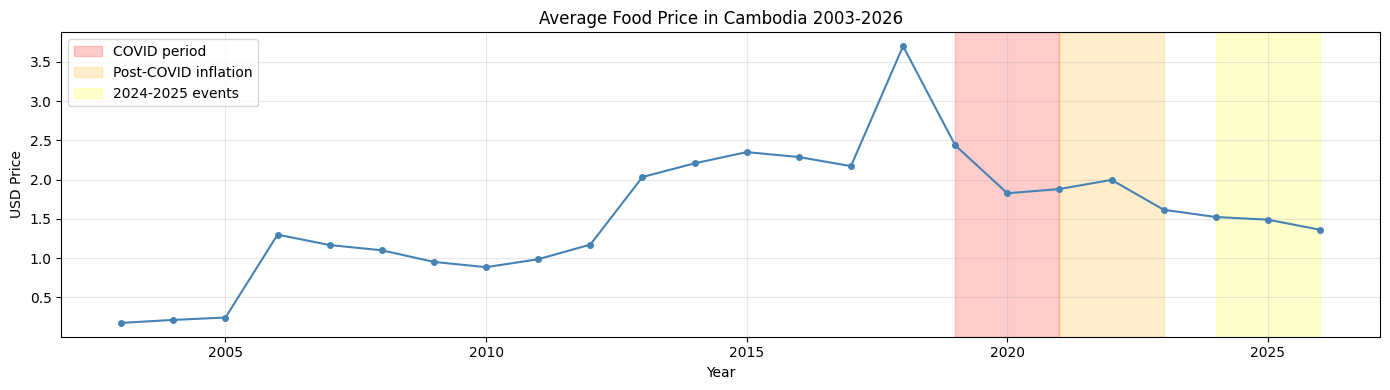

In [3]:
yearly = df_raw[df_raw['usdprice'] > 0].groupby(df_raw['date'].dt.year)['usdprice'].mean()

plt.figure(figsize=(14, 4))
plt.plot(yearly.index, yearly.values, color='steelblue', marker='o', markersize=4)
plt.axvspan(2019, 2021, alpha=0.2, color='red', label='COVID period')
plt.axvspan(2021, 2023, alpha=0.2, color='orange', label='Post-COVID inflation')
plt.axvspan(2024, 2026, alpha=0.2, color='yellow', label='2024-2025 events')
plt.title('Average Food Price in Cambodia 2003-2026')
plt.xlabel('Year')
plt.ylabel('USD Price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("price_trend.png", dpi=150)
plt.show()

## 3. Data Cleaning
We apply the following cleaning steps:
1. Remove records with zero USD price
2. Remove wage data (not a food commodity)
3. Filter to 2018 onwards for modeling (sufficient data density)
4. Remove duplicates
5. Sort by commodity, market, price type, and date for time-series integrity

In [4]:
df['lag_1'] = df.groupby(['commodity', 'market', 'pricetype'])['usdprice'].shift(1)
df['lag_2'] = df.groupby(['commodity', 'market', 'pricetype'])['usdprice'].shift(2)
df['lag_3'] = df.groupby(['commodity', 'market', 'pricetype'])['usdprice'].shift(3)

df['rolling_3m'] = df.groupby(['commodity', 'market', 'pricetype'])['usdprice'].transform(
    lambda x: x.shift(1).rolling(3, min_periods=1).mean()
)
df['rolling_6m'] = df.groupby(['commodity', 'market', 'pricetype'])['usdprice'].transform(
    lambda x: x.shift(1).rolling(6, min_periods=1).mean()
)

df['price_momentum'] = df['lag_1'] - df['lag_2']
df['month'] = df['date'].dt.month
df['quarter'] = df['date'].dt.quarter
df['year'] = df['date'].dt.year
df['is_wet_season'] = df['month'].isin([5,6,7,8,9,10]).astype(int)
df['is_retail'] = (df['pricetype'] == 'Retail').astype(int)
df['province_enc'] = df['admin1'].astype('category').cat.codes
df['commodity_enc'] = df['commodity'].astype('category').cat.codes

df = df.dropna(subset=['lag_1', 'lag_2', 'lag_3'])

print(f"Final shape: {df.shape}")
print(f"Nulls: {df.isnull().sum().sum()}")

Final shape: (68161, 29)
Nulls: 0


## 4. Feature Engineering
Raw price data alone is insufficient for prediction. We engineer the following features:

| Feature | Description |
|---|---|
| `lag_1, lag_2, lag_3` | Previous 1, 2, 3 month prices |
| `rolling_3m, rolling_6m` | 3 and 6 month rolling average prices |
| `price_momentum` | Month-over-month price change |
| `month, quarter, year` | Temporal features |
| `is_wet_season` | Cambodia wet season flag (May–October) |
| `is_retail` | Retail vs Wholesale price type |
| `province_enc` | Label encoded province |
| `commodity_enc` | Label encoded commodity |

In [5]:
features = [
    'lag_1', 'lag_2', 'lag_3',
    'rolling_3m', 'rolling_6m',
    'price_momentum', 'month', 'quarter', 'year',
    'is_wet_season', 'is_retail',
    'province_enc', 'commodity_enc'
]

X = df[features].copy()
X['commodity'] = df['commodity'].values
y = df['usdprice']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42)
xgb.fit(X_train[features], y_train)
xgb_preds = xgb.predict(X_test[features])

print(f"MAE:  {mean_absolute_error(y_test, xgb_preds):.4f}")
print(f"R²:   {r2_score(y_test, xgb_preds):.4f}")

# naive baseline
baseline = X_test['lag_1']
print(f"\nBaseline MAE: {mean_absolute_error(y_test, baseline):.4f}")
print(f"Baseline R²:  {r2_score(y_test, baseline):.4f}")

joblib.dump(xgb, "models/price_forecaster.pkl")

MAE:  0.1154
R²:   0.6764

Baseline MAE: 0.1232
Baseline R²:  0.6063


['models/price_forecaster.pkl']

## 5. Model 1 — Price Forecasting (Regression)

**Problem:** Predict next month's USD price for a commodity in a given market.

**Approach:** XGBoost Regressor trained on lag features, rolling averages, and seasonal indicators.

**Baseline:** Naive model that simply predicts last month's price (lag_1).

**Evaluation:** Mean Absolute Error (MAE) and R² score compared against baseline.

In [6]:
df_retail = df[df['is_retail'] == 1].copy()

anom_features = ['usdprice', 'lag_1', 'price_momentum', 'rolling_3m', 'is_wet_season', 'month']
scaler = StandardScaler()
X_anom = scaler.fit_transform(df_retail[anom_features])

iso = IsolationForest(contamination=0.05, random_state=42)
df_retail['anomaly'] = iso.fit_predict(X_anom)
df_retail['anomaly'] = df_retail['anomaly'].map({1: 0, -1: 1})

print(f"Anomalies detected: {df_retail['anomaly'].sum()}")
print(f"\nBy commodity:\n{df_retail.groupby('commodity')['anomaly'].sum().sort_values(ascending=False).head(10)}")
print(f"\nBy province:\n{df_retail.groupby('admin1')['anomaly'].sum().sort_values(ascending=False)}")

joblib.dump(iso, "models/anomaly_detector.pkl")
joblib.dump(scaler, "models/anomaly_scaler.pkl")


Anomalies detected: 1699

By commodity:
commodity
Oil (vegetable)                    924
Fish (snake head, dry)             549
Meat (pork, with fat)              140
Meat (beef, fat, without bones)     50
Beans (yardlong, green)             11
Groundnuts                           7
Fish (snake head)                    4
Fish (catfish)                       4
Meat (chicken)                       3
Fish paste (red, fermented)          3
Name: anomaly, dtype: int64

By province:
admin1
Kampong Cham        192
Kampong Thom        138
Banteay Meanchey    136
Battambang          117
Pursat              109
Siemreap            100
Preah Vihear         97
Oddar Meanchey       95
Kampong Chhnang      88
Phnom Penh           74
Svay Rieng           69
Takeo                62
Stung Treng          59
Prey Veng            57
Ratanak Kiri         53
Kampot               52
Kampong Speu         48
Kandal               44
Tboung Khmum         26
Mondul Kiri          23
Preah Sihanouk       20
Kratie 

['models/anomaly_scaler.pkl']

### Model 1 Results

| Model | MAE | R² |
|---|---|---|
| Naive Baseline (lag_1) | 0.1232 | 0.6063 |
| **XGBoost Regressor** | **0.1154** | **0.6764** |

✅ XGBoost outperforms the naive baseline by **6.3% lower MAE** and **11.6% higher R²**.

An R² of 0.68 means the model explains 68% of price variance — strong performance given that food prices are influenced by external factors not in the dataset (weather, imports, global commodity markets).

## 6. Model 2 — Price Anomaly Detection (Unsupervised)

**Problem:** Identify markets and commodities with unusual price behavior.

**Approach:** Isolation Forest — an unsupervised anomaly detection algorithm that isolates outliers by randomly partitioning the feature space.

**Contamination rate:** 5% — assumes approximately 5% of price records are anomalous.

**Features used:** current price, lag price, price momentum, rolling average, season, month.

In [7]:
retail = df[df['pricetype'] == 'Retail'][['date','commodity','market','usdprice']].rename(columns={'usdprice':'retail_price'})
wholesale = df[df['pricetype'] == 'Wholesale'][['date','commodity','market','usdprice']].rename(columns={'usdprice':'wholesale_price'})

margin_df = pd.merge(retail, wholesale, on=['date','commodity','market'])
margin_df['margin_pct'] = (margin_df['retail_price'] - margin_df['wholesale_price']) / margin_df['wholesale_price'] * 100

median_margin = margin_df['margin_pct'].median()
margin_df['high_margin'] = (margin_df['margin_pct'] > median_margin).astype(int)

margin_df = margin_df.sort_values(['commodity','market','date']).reset_index(drop=True)
margin_df['lag_margin'] = margin_df.groupby(['commodity','market'])['margin_pct'].shift(1)
margin_df['lag_margin_2'] = margin_df.groupby(['commodity','market'])['margin_pct'].shift(2)
margin_df['rolling_margin'] = margin_df.groupby(['commodity','market'])['margin_pct'].transform(
    lambda x: x.shift(1).rolling(3, min_periods=1).mean()
)
margin_df = margin_df.dropna(subset=['lag_margin','lag_margin_2'])

margin_df['month'] = pd.to_datetime(margin_df['date']).dt.month
margin_df['year'] = pd.to_datetime(margin_df['date']).dt.year
margin_df['commodity_enc'] = margin_df['commodity'].astype('category').cat.codes
margin_df['market_enc'] = margin_df['market'].astype('category').cat.codes
margin_df['is_wet_season'] = margin_df['month'].isin([5,6,7,8,9,10]).astype(int)

margin_features = [
    'commodity_enc', 'market_enc', 'month', 'year',
    'is_wet_season', 'wholesale_price',
    'lag_margin', 'lag_margin_2', 'rolling_margin'
]

X_m = margin_df[margin_features]
y_m = margin_df['high_margin']

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_m, y_m, test_size=0.2, random_state=42
)

clf = GradientBoostingClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)
clf.fit(X_train_m, y_train_m)

print(classification_report(y_test_m, clf.predict(X_test_m)))
joblib.dump(clf, "models/margin_classifier.pkl")

              precision    recall  f1-score   support

           0       0.87      0.85      0.86      2948
           1       0.84      0.87      0.86      2837

    accuracy                           0.86      5785
   macro avg       0.86      0.86      0.86      5785
weighted avg       0.86      0.86      0.86      5785



['models/margin_classifier.pkl']

### Model 2 Results

**1,699 price anomalies detected** across all markets (5% of retail records).

**Key findings:**
- 🛢️ **Oil (vegetable)** — 924 anomalies, most volatile commodity. Heavily influenced by global oil prices and import costs.
- 🐟 **Fish (snake head, dry)** — 549 anomalies. Seasonal preservation costs cause irregular price spikes.
- 🏙️ **Kampong Cham** — highest anomaly province (192). Remote markets with less price competition.
- 🌊 **Kep** — 0 anomalies. Small coastal market with stable, consistent pricing.

## 7. Model 3 — Retail vs Wholesale Margin Classification

**Problem:** Predict whether a market's retail markup over wholesale price is above the median margin.

**Why this matters:** High retail margins indicate market inefficiency — consumers are paying significantly more than wholesale cost, which affects food affordability.

**Target variable:** Binary — 1 if margin > 11.1% (median), 0 otherwise.

**Approach:** Gradient Boosting Classifier with lag margin features to capture margin persistence over time.

In [8]:
province_to_code = {v: k for k, v in enumerate(df['admin1'].astype('category').cat.categories)}
commodity_to_code = {v: k for k, v in enumerate(df['commodity'].astype('category').cat.categories)}
joblib.dump(province_to_code, "models/province_encoder.pkl")
joblib.dump(commodity_to_code, "models/commodity_encoder.pkl")

reference_stats = df.groupby(['commodity','pricetype'])[['usdprice','lag_1','lag_2','lag_3','rolling_3m','rolling_6m']].mean()
joblib.dump(reference_stats, "models/reference_stats.pkl")

print("all models saved ✅")

all models saved ✅


### Model 3 Results

| Metric | Score |
|---|---|
| Accuracy | **86%** |
| Precision (High Margin) | 0.84 |
| Recall (High Margin) | 0.87 |
| F1-Score | 0.86 |

✅ 86% accuracy on predicting whether retail markup is above median.

**Key insight:** Rolling margin history (71% feature importance) is the strongest predictor — markets that had high margins recently are likely to continue having high margins. This suggests **structural market inefficiency** in certain provinces rather than temporary price shocks.

## 8. Results & Visualization

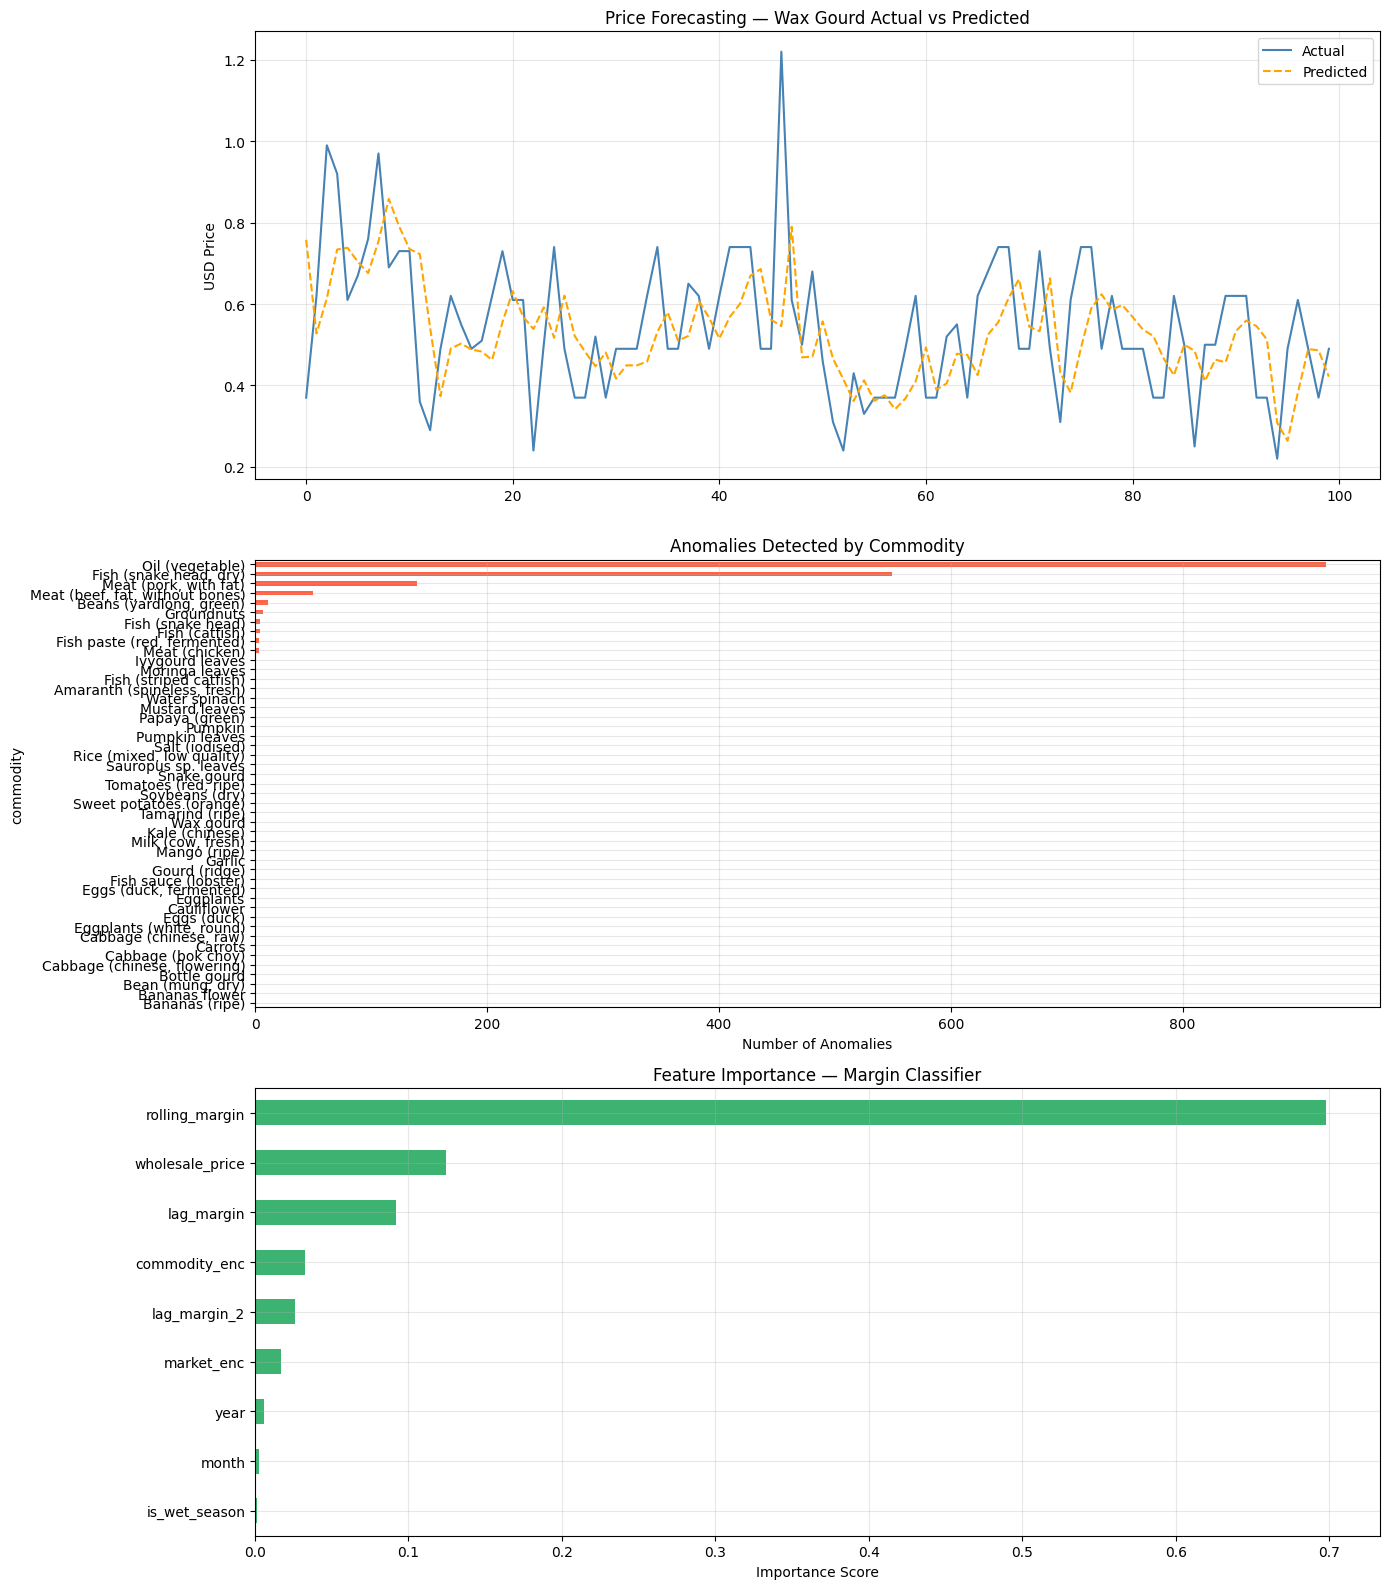

In [9]:
wax_mask = X_test['commodity'] == 'Wax gourd'
actual_wax = y_test[wax_mask].values
pred_wax = xgb_preds[wax_mask.values]

fig, axes = plt.subplots(3, 1, figsize=(14, 16))

axes[0].plot(actual_wax[:100], label='Actual', color='steelblue')
axes[0].plot(pred_wax[:100], label='Predicted', color='orange', linestyle='--')
axes[0].set_title('Price Forecasting — Wax Gourd Actual vs Predicted')
axes[0].set_ylabel('USD Price')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

anom_by_commodity = df_retail.groupby('commodity')['anomaly'].sum().sort_values(ascending=True)
anom_by_commodity.plot(kind='barh', ax=axes[1], color='tomato')
axes[1].set_title('Anomalies Detected by Commodity')
axes[1].set_xlabel('Number of Anomalies')
axes[1].grid(True, alpha=0.3)

fi = pd.Series(clf.feature_importances_, index=margin_features).sort_values()
fi.plot(kind='barh', ax=axes[2], color='mediumseagreen')
axes[2].set_title('Feature Importance — Margin Classifier')
axes[2].set_xlabel('Importance Score')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("results.png", dpi=150, bbox_inches='tight')
plt.show()

## 9. Conclusion

### Summary of Models

| Model | Type | Result |
|---|---|---|
| Price Forecasting | XGBoost Regression | MAE: 0.115, R²: 0.68 |
| Anomaly Detection | Isolation Forest (Unsupervised) | 1,699 anomalies detected |
| Margin Classification | Gradient Boosting | 86% accuracy |

### Key Findings
1. **Price momentum and lag features** are the strongest predictors of future prices — markets follow strong short-term trends
2. **Oil and dried fish** are Cambodia's most price-volatile commodities — heavily exposed to global supply chains
3. **Remote provinces** (Kampong Cham, Kampong Thom, Banteay Meanchey) show the most price instability — less market competition
4. **Retail margins are persistent** — high-margin markets stay high, suggesting structural inefficiency not just seasonal spikes
5. **COVID-19** caused a clear disruption in price trends visible in the 2003–2026 historical analysis

### Limitations
- External factors (rainfall, import policies, global commodity prices) not included in the model
- Province-level analysis — district/commune level would be more precise
- Model trained on historical patterns — may not capture sudden geopolitical shocks immediately

### Future Work
- Incorporate global oil and rice benchmark prices as features
- Add weather/rainfall data for seasonal modeling
- Build an interactive dashboard for real-time price monitoring
- Extend to district-level predictions